# E70: Does removing the old count hurt the reusing task more than the new one?

**The answer.** Only with a six-direction removal, and that is not the test we set out to run. The one direction the regression probe finds reads the count perfectly, yet removing it costs the pretrained model nothing and costs both fine-tuned tasks under one percent of their gain. So the filed headline, no separation, says nothing about the definition. Removing the softmax probe's six directions does hurt the pretrained model, and costs the reusing task more at blocks 2 to 5, though the new task loses far more than predicted.


## What we were trying to test

`GOALS.md` asks whether post-training teaches new capabilities or strengthens existing ones. `decisions.md` defines that without any decomposition, after Jain, Kirk, Lubana et al. 2024. A model possesses a capability if a linear readout trained on pretraining data recovers it. A fine-tune reuses it if the new map is some function of that reading. And reuse needs a causal claim: taking the readout's direction away must break the fine-tuned behaviour. That last clause had never been read on a pair whose answer is known by construction.

**The model.** LOW is a small transformer of 6 blocks and width 192, pretrained to count the letter a when asked `C a 40`.

**The pair.** Every state is LOW fine-tuned on `C b 40` rows of natural text.

- **Task P** answers the count of a plus one. It reuses the old count, by construction.
- **Task N** answers the count of b. It needs a new count, by construction.

Both tasks ran at two learning rates and five seeds, saved at 1,000 and 10,000 steps, the same grid as an earlier stage. Those states were lost with an old clone, so LOW and all 20 runs were retrained from the same code and seeds. The filed rule reads the 20 states at 10,000 steps.

**Two probes on LOW,** each trained per block on `C a 40` rows, read at the `=` position, with no possession threshold.

- **The ridge probe** regresses the count on the residual and gives one direction, its unit weight vector. This is the task as asked, and the filed headline.
- **The softmax probe** predicts the count as a class. The classes it sees are the counts 10 to 16, so its centred columns span six directions out of 192. It is reported beside the ridge probe, to ask whether one direction misses a count held in several.

**The removal.** With $h$ the residual after block $b$ at `=` and $U$ an orthonormal basis of the probe's directions, $h$ becomes $h - U U^\top h$ at that one position. Later blocks still read the text.

**The score.** Let $D_{\text{state}}$ be the state's mean drop in the log-odds of its own answer under the removal, $D_{\text{LOW}}$ be LOW's drop for the same answer on the same rows, and $G$ be the state's mean log-odds gain over LOW. The share of the gain lost is $(D_{\text{state}} - D_{\text{LOW}}) / G$. A share of 0 means the state lost no more than LOW did, and 1 means the whole gain went. The raw share is $D_{\text{state}} / G$.

**The controls,** each read in the same job, and what each rules out:

- LOW's count accuracy against the old run, to rule out a different model under the same name.
- LOW's own log-odds drop under the removal, on `C a 40` rows, to rule out a removal that does nothing. If it costs LOW nothing, a null on the tasks means nothing.
- 20 random directions per block, or 20 random six-direction subspaces, on LOW and on every state. The 95th percentile of their size sets the band at each block, so any removal of that size has to beat it.

**The rule.** At a block, the smallest P share minus the largest N share must exceed that block's band. All ten states of a side must clear all ten of the other.


## What we expected, and why

We expected the removal to work on LOW, at least at the last block, since a readout that reads the count should be using what the model uses.

We expected the rule to hold. P's answer is a function of the old count, so removing the count should cost P a lot: over half its gain at block 6. N's answer does not depend on the count of a, so N should sit near the band at blocks 1 to 5, and might rise at block 6, where every answer shares the output head.

We expected the function test to split the pair cleanly. A table from LOW's reading to the state's answer should score near the probe's accuracy on P and near its floor on N.

The plan named one blind spot in advance: the count of a and the count of b are correlated on these rows, so a direction shared between them would cost N as well.


In [1]:
import json
from pathlib import Path

import numpy as np
from IPython.display import Image, Markdown, display

ROOT = Path("../experiments/pcfg_anchors")
RES = json.loads((ROOT / "results" / "e70.json").read_text())
FIG = ROOT / "figures"


def show(name):
    display(Image(filename=str(FIG / name), width=760))


def table(head, rows):
    lines = ["| " + " | ".join(head) + " |", "|" + "---|" * len(head)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


p, c = RES["probes"], RES["control"]
print(f"LOW count of a {RES['low']['count_a']:.5f}, old run {RES['low']['count_a_a1']:.5f}")
print(f"correlation of count(a) and count(b) on 'C b 40' rows {p['corr_count_a_count_b_on_C_b_40']:.2f}")
ten_k = [f for f in RES["finetunes"].values() if f["step"] == 10000]
print(f"10K states: lowest task accuracy {min(f['task_acc'] for f in ten_k):.4f}, "
      f"largest gap to the earlier stage {max(abs(f['task_acc'] - f['task_acc_c1b']) for f in ten_k):.4f}")
table(["block", "ridge accuracy", "softmax accuracy", "softmax, shuffled labels", "softmax, earlier run"],
      [[i + 1, f"{p['ridge']['acc_a'][i]:.3f}", f"{p['softmax']['acc_a'][i]:.3f}", f"{p['softmax']['shuffled_a'][i]:.3f}",
        f"{p['softmax']['acc_a_a1c'][i]:.3f}"] for i in range(6)])


LOW count of a 0.99975, old run 0.99975
correlation of count(a) and count(b) on 'C b 40' rows -0.50
10K states: lowest task accuracy 1.0000, largest gap to the earlier stage 0.0005


| block | ridge accuracy | softmax accuracy | softmax, shuffled labels | softmax, earlier run |
|---|---|---|---|---|
| 1 | 0.380 | 0.356 | 0.331 | 0.342 |
| 2 | 0.998 | 0.919 | 0.331 | 0.871 |
| 3 | 1.000 | 0.972 | 0.335 | 0.916 |
| 4 | 1.000 | 0.995 | 0.339 | 0.985 |
| 5 | 1.000 | 0.998 | 0.354 | 0.999 |
| 6 | 1.000 | 1.000 | 0.356 | 1.000 |

## What we observed

### Does LOW hold the count of a?

**Reading it.** Yes, from block 2 on, and the first two controls pass. LOW retrained to its old accuracy exactly, and every 10K state performs its own task perfectly. The table above shows both probes on held-out `C a 40` rows. The ridge probe always beats its floor of 0.36, the rate of always guessing the commonest count, and it reads almost perfectly from block 2. The softmax probe beats its shuffled-label twin by a wide margin from block 2 and matches the earlier run at blocks 5 and 6, reading a little higher at blocks 2 and 3. At block 1 neither probe reads much.


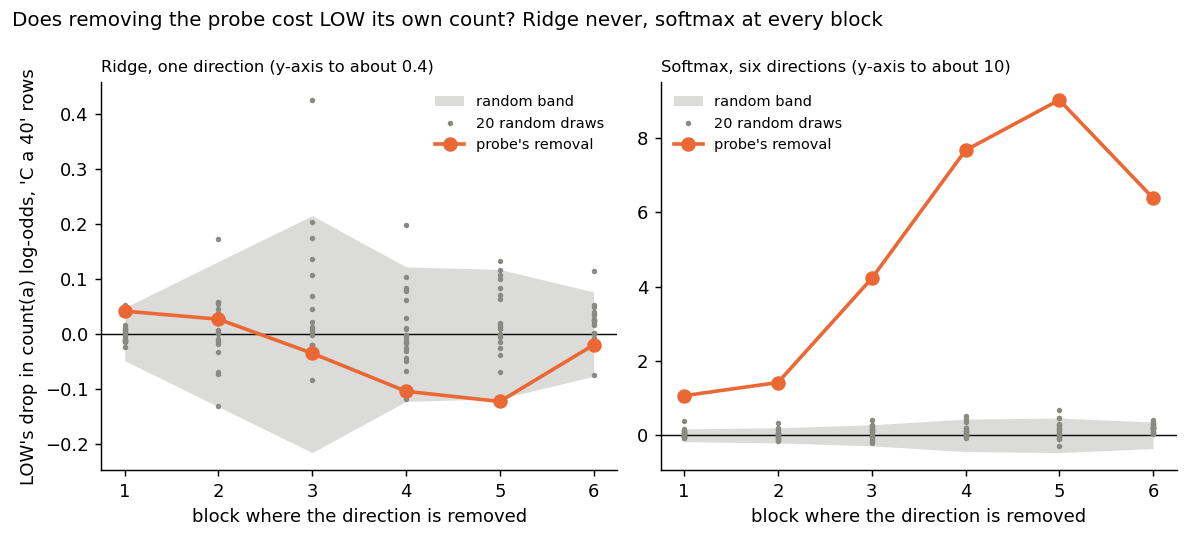

In [2]:
show("e70_low.png")


### Does removing the probe cost LOW its own count?

**Reading it.** The ridge direction does not, at any block, and the softmax directions do, at every block. The figure's left panel plots LOW's log-odds drop against 20 random single directions. The ridge removal stays inside or under the grey band everywhere, and at blocks 4 and 5 it nudges the log-odds up, not down. Single random directions moved LOW by more than the probe's direction did. The right panel, on a scale about twenty times larger, has the softmax removal above its band at all six blocks, at most 9 log-odds against a band of about 0.5.

So one direction that reads the count perfectly can be taken away with no effect on the model that holds the count. Why is unexplained and open. Whatever follows on the ridge probe has no working control under it.


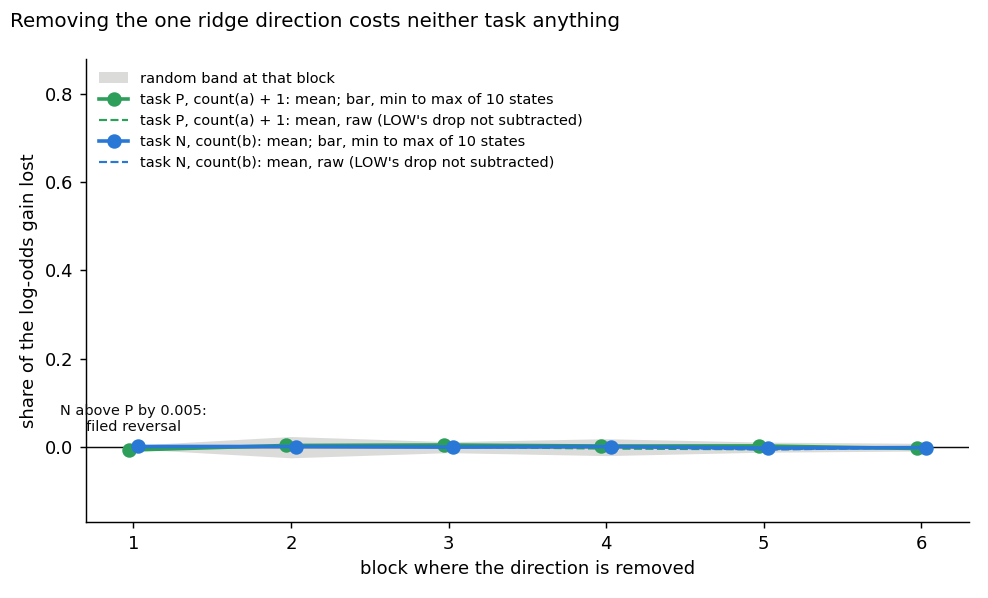

In [3]:
show("e70_ridge.png")


### Does removing the one ridge direction cost task P more than task N?

**Reading it.** No: it costs neither task anything. The filed verdict is "does not separate", and this misses our lean that the rule would hold. Every share at every block lies within 0.01 of zero, on the same axes as the next figure. This cannot be read as a negative about the definition, because the removal does nothing on LOW either. The filed rule also returned a reversal at block 1, with N above P by 0.005 against a band of 0.004. That is half a percent of the gain, at the block where this probe reads barely above its floor, on a removal with no effect on LOW.


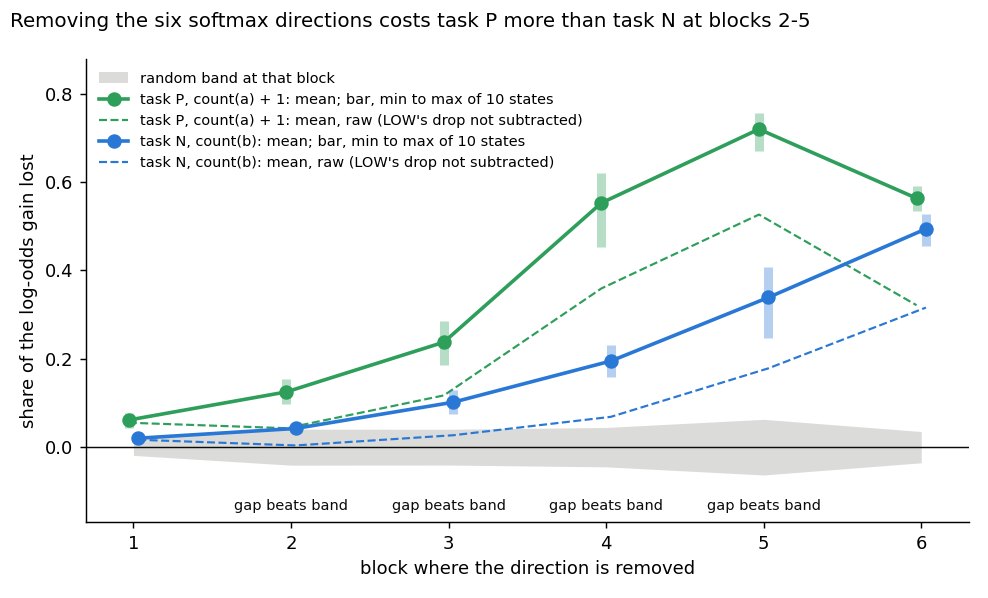

In [4]:
show("e70_softmax.png")


### Does removing the six softmax directions cost task P more than task N?

**Reading it.** Yes at blocks 2 to 5, by the filed rule, but it is a difference of degree and not the clean split we predicted. In the figure the whole P range clears the whole N range by more than the band at those four blocks, most widely at block 5, where P loses 0.72 of its gain and N loses 0.34. At blocks 1 and 6 the rule does not hold. P passes the half-gain mark at block 6, as leaned, with 0.56. N misses its prediction of staying near the band up to block 5. It reads 0.20 at block 4 and 0.34 at block 5, against bands of 0.045 and 0.063.

This removes six directions, not the one the task named, so it does not by itself answer the task as asked.

**What subtracting LOW's drop does.** The scored share subtracts LOW's drop, and LOW's drop on these rows is negative. Removing its count directions raises LOW's log-odds of P's answer by about 5 at blocks 4 and 5, and of N's answer by about 3. Subtracting a negative number adds to the share, as the gap between the solid and dashed lines shows: about 0.19 for P, and 0.13 to 0.16 for N. In the raw share the gap between the tasks survives at blocks 4 and 5: the smallest P is 0.28 and 0.50, and the largest N is 0.08 and 0.22. At blocks 2 and 3 the raw gap is 0.01 and 0.04, under the scored band, so those two blocks lean on the subtraction. At block 6 the raw shares are equal, at 0.32.

**A candidate for N's rise, not a cause.** The count of a and the count of b correlate at -0.50 on these rows, the blind spot the plan named. A direction shared by the two counts would cost N as well. This run did not test that.

**At 1,000 steps** the shares run higher than at 10,000 on both tasks, by up to about 0.14 on N and 0.12 on P. Five of the ten N states there have not yet learned the task, at about 0.49 accuracy, so the filed rule leaves 1K out. The gain is also smaller there, about 21 log-odds on P and 11 on N against 26 and 22, while LOW's subtracted term stays fixed.


In [5]:
rows = RES["r2"]["softmax"]["rows"]
mean = lambda r, name, key="shares": np.mean(list(r[key][name].values()))
table(["block", "P share, raw", "N share, raw", "band", "rule"],
      [[r["block"], f"{mean(r, 'P_10000'):.2f}, {mean(r, 'P_10000', 'shares_raw'):.2f}",
        f"{mean(r, 'N_10000'):.2f}, {mean(r, 'N_10000', 'shares_raw'):.2f}", f"{r['band']:.3f}", r["call"]] for r in rows])
gf = RES["gf_by_block"]
floor = {t: next(RES["states"][s]["gf"][0]["floor"] for s in gf[f"{t}_10000"]) for t in "PN"}
table(["block", "table on P", "floor on P", "table on N", "floor on N"],
      [[i + 1, f"{np.mean([v[i] for v in gf['P_10000'].values()]):.3f}", f"{floor['P']:.3f}",
        f"{np.mean([v[i] for v in gf['N_10000'].values()]):.3f}", f"{floor['N']:.3f}"] for i in range(6)])


| block | P share, raw | N share, raw | band | rule |
|---|---|---|---|---|
| 1 | 0.06, 0.06 | 0.02, 0.02 | 0.019 | neither |
| 2 | 0.13, 0.04 | 0.04, 0.00 | 0.041 | holds |
| 3 | 0.24, 0.12 | 0.10, 0.03 | 0.041 | holds |
| 4 | 0.55, 0.36 | 0.20, 0.07 | 0.045 | holds |
| 5 | 0.72, 0.53 | 0.34, 0.18 | 0.063 | holds |
| 6 | 0.56, 0.32 | 0.49, 0.32 | 0.035 | neither |

| block | table on P | floor on P | table on N | floor on N |
|---|---|---|---|---|
| 1 | 0.367 | 0.353 | 0.343 | 0.357 |
| 2 | 0.997 | 0.353 | 0.386 | 0.357 |
| 3 | 1.000 | 0.353 | 0.387 | 0.357 |
| 4 | 1.000 | 0.353 | 0.387 | 0.357 |
| 5 | 1.000 | 0.353 | 0.387 | 0.357 |
| 6 | 1.000 | 0.353 | 0.387 | 0.357 |

### Is each task's answer a function of LOW's reading?

**Reading it.** Yes for P, no for N, as predicted, on all ten states of each side at 10K. The second table is a lookup from LOW's rounded ridge reading to the state's answer, fitted on half the rows and scored on the other half. On P it follows the probe's accuracy and reaches 1 from block 3. On N it stays at 0.39 from block 2, against a floor of 0.36. The reading comes from the ridge probe, so this direction reads the count well enough to give P's answer exactly, while removing it does nothing. This test reads answers alone, and the answers are fixed by each task's construction, so it checks the pair more than it checks the removal.


## What we learned

The definition's possession and function clauses behave as they should on a pair with known labels. Its causal clause, read as the removal of one regression direction, gave no reading, because that removal has no effect even on the model that holds the count. A wider removal of six softmax directions has an effect on LOW and costs P more than N at blocks 2 to 5, with N also losing a lot. So for `GOALS.md`'s question of new against existing, the one-direction test on known labels remains unanswered. The six-direction result is a provisional sign that a causal removal can carry the distinction, by degree, not yet a ground truth for scoring cheap methods on Qwen.

## How compelling is the evidence

The controls are strong for what they cover: 20 states, ten per side, five seeds and two learning rates, with bands from the same job.

- **Blind spots.** The removal misses a count held non-linearly and anything later blocks re-read from the text. It also cannot tell a direction used by both counts from a mechanism N shares.
- **Log-odds are not answers.** These states are very sure of their answers, with a mean probability above 0.999 on every 10K state, so a large log-odds drop can leave the answer in place. The share of the gain in nats, recorded but not scored, reads 0.16 and 0.31 for P at blocks 4 and 5 against 0.002 and 0.013 for N. It reads about 0.001 on both at block 6. The median row loses only 0.2 nats on P at block 5. No accuracy after removal was recorded. This reading is provisional and has no filed rule.
- **Check.** No independent check was run, and none is claimed. This is one retrain of LOW, with one probe seed.

## Surprises

**A filed reversal, and a filed miss, on the headline.** We predicted the one-direction rule would hold, and instead it does not separate, with N above P at block 1 by half a percent. The size is tiny and the removal has no effect on LOW, so we read no mechanism into it.

**The direction that reads the count does nothing when removed.** A regression direction reads the count at accuracy 1 from block 3 and supports a perfect lookup for P, yet taking it away leaves LOW's log-odds inside the random band. We cannot explain this.

**N loses much more than predicted under the six directions.** N reads 0.34 at block 5, against a predicted value near 0.06.

Narrow: the softmax probe read up to 0.06 above its earlier run at blocks 2 and 3, and neither probe read consistently lower on `C b 40` rows at early blocks, as we had predicted.

## What next

- **Remove a direction chosen by where the count actually varies in the residual,** the covariance of the residual with the count, not the regression weights, on LOW first against its random band, about 15 minutes at $0. If LOW loses log-odds, read P and N: separation would give the one-direction reading the task named, and no separation would mean one direction cannot serve as ground truth here. If LOW loses nothing again, the one-direction test is closed and the six-direction result is the only reading left.
- **Test N's rise.** Repeat the six-direction removal on rows where the two counts are uncorrelated. A fall in N would support the shared-direction reading, and no fall would rule it out.
- **Record accuracy after removal,** so a share of log-odds can be read as answers lost or kept.


## Scorecard

Verdicts are the filed rules' own. A probe's "no teeth" means its drop on LOW did not exceed its random band.

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| R1a | LOW retrains to its old count | within 0.01 of 0.99975 | 0.99975 | holds |
| R1b | a removal costs LOW, or stop | drop above band at some block, some probe | ridge at none, softmax at all six | no stop; ridge no teeth |
| R2 ridge, headline | P loses more than N | smallest P minus largest N above band, at a block from 1 to 5 | gaps within 0.012, none above band | does not separate; lean missed |
| R2 reversal | N above P | smallest N minus largest P above band | block 1, 0.0050 against 0.0042 | reversal, filed, half a percent |
| R2 softmax, beside it | P loses more than N | as above | gaps 0.052, 0.056, 0.224, 0.262 at blocks 2-5, bands 0.041, 0.041, 0.045, 0.063 | separates |
| Lean, P | high late, over 0.5 at block 6 | mean, 10K | softmax 0.56; ridge -0.003 | met on softmax, not on ridge |
| Lean, N | near the band at blocks 1-5 | mean, 10K | softmax 0.10, 0.20, 0.34 at blocks 3-5, bands 0.041, 0.045, 0.063 | missed on softmax |
| Lean, LOW | above band at least at block 6 | drop against band | softmax 6.38 against 0.36; ridge -0.02 against 0.08 | met on softmax, not on ridge |
| Lookup | P near probe, N near floor | 10K | P 1.00 at block 6; N 0.387, floor 0.357 | as expected |
| Task accuracy | close to the earlier stage | logged | 10K all 1.0, within 0.0005; 1K within 0.015 | as expected |

## Not run

- A one-direction removal chosen by covariance, or any direction other than the ridge weights.
- The six-direction removal on rows where the two counts are uncorrelated, so the -0.50 correlation is untested.
- Accuracy after removal.
- Raw-share bands: random draws were scored only as the subtracted share.
- Pruning and reverse fine-tuning on these retrained states; the earlier stage's readings stand and are quoted, not rerun.
- A second LOW or a second probe seed.
- VPD and Qwen.
- Carrying the lookup to count values it never saw: no held-out rule is filed.
- An independent check.

## Departures from the literature

- **Possession.** Jain et al. 2024 threshold a softmax probe for possession. We report by block with no threshold, by the user's instruction, against "filed before any run" in `decisions.md`, and use a ridge regression as the headline, because a removal needs a direction.
- **Causal test.** Jain et al. use pruning and reverse fine-tuning. We remove a probe's direction or subspace at `=`, as in `decisions.md`'s mechanistic row, because this pair's labels are known by construction.
- **Shuffled-label control.** Hewitt and Liang 2019 use random labels per input type. We permute labels within each batch, since these inputs carry no information about them.

## Provenance

Plan `reports/plans/2026-11-03_plan_e70-existing-new-counting.md`. Rules `experiments/pcfg_anchors/results/predictions_e70.json`. Code `experiments/pcfg_anchors/e70.py`, `src/commute/removal.py`. Results `experiments/pcfg_anchors/results/e70.json`, commit a6103fc. Figures `experiments/pcfg_anchors/figures/e70_{low,ridge,softmax}.png` from `plot_e70.py`. Report `reports/analyses/2026-11-03_analysis_e70-existing-new-counting.md`. MATS L40, `debug`, jobs 50203, 50242, 50298, 50311, 50361, 50363, 11:17 to 13:17 on 2026-11-03, $0.
